# Practical 11: Sunspot Data with a Gamma Model

**Dataset:** Datasets/sunspots.csv (monthly mean total sunspot number, January 1749 to November 2018)

**Aim:** Plot the data, model the counts with a gamma distribution, run a Metropolis sampler for the gamma parameters a (shape) and b (scale), and predict a and b.

The counts are shifted by +1 inside the model because a gamma distribution cannot take the value 0.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

sun = pd.read_csv("../Datasets/../Datasets/sunspots.csv")
date_col = [c for c in sun.columns if "date" in c.lower()][0]
sun["date"] = pd.to_datetime(sun[date_col])
sun["count"] = sun.iloc[:, -2 if sun.columns[-1] == "date" else -1].astype(float)
counts = sun["count"].to_numpy()
print("Rows        :", len(sun))
print("First month :", sun["date"].min().strftime("%B %Y"))
print("Last month  :", sun["date"].max().strftime("%B %Y"))
sun[["date", "count"]].head()

Rows        : 3239
First month : January 1749
Last month  : November 2018


        date  count
0 1749-01-31   15.8
1 1749-02-28    4.7
2 1749-03-31   11.9
3 1749-04-30   14.7
4 1749-05-31   17.4

**Result:** The data has 3239 monthly values from January 1749 to November 2018.

### Step 1: Plot the data over the years

Mean count   : 74.08
Highest value: 417.0 in March 1852


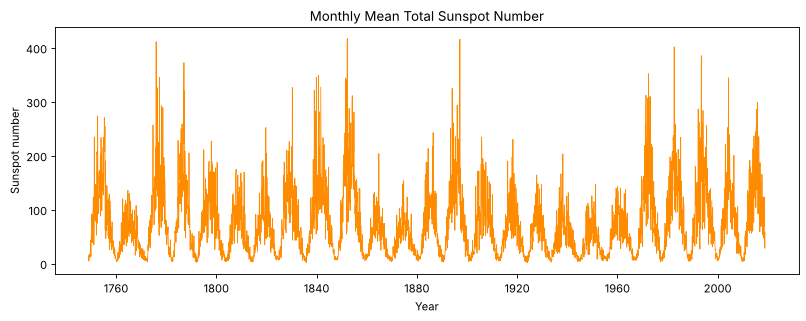

In [2]:
plt.figure(figsize=(12, 4))
plt.plot(sun["date"], sun["count"], color="darkorange", linewidth=0.7)
plt.title("Monthly Mean Total Sunspot Number")
plt.xlabel("Year")
plt.ylabel("Sunspot number")
plt.show()
peak_row = sun.loc[sun["count"].idxmax()]
print("Mean count   :", round(counts.mean(), 2))
print("Highest value:", peak_row["count"], "in", peak_row["date"].strftime("%B %Y"))

**Result:** The series rises and falls in repeating waves, which are the solar cycles of about 11 years. The mean is 74.08 and the highest value is 417.0 in March 1852. Values are never negative and a few high peaks make the data skewed to the right, which is why a gamma distribution is a reasonable model.

### Step 2: Gamma model with a new cycle every 12 years

The data is cut into blocks of 144 months (12 years). The position inside the block resets to zero at the start of every block, and a gamma shaped curve is fitted to the average profile of the blocks.

Number of 12-year blocks: 23
        mean    max
cycle              
0      88.38  273.4
1      45.70  135.9
2      96.82  411.3
3      89.80  372.4
4      69.62  226.5
5      69.21  252.2
6      74.13  326.4
7      94.16  348.7
Fitted shape a: 1.217
Fitted scale b: 17.831


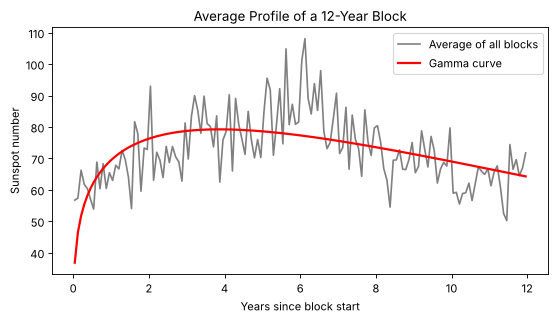

In [3]:
sun["month_no"] = np.arange(len(sun))
sun["cycle"] = sun["month_no"] // 144
sun["year_in_cycle"] = (sun["month_no"] % 144 + 0.5) / 12
cycle_table = sun.groupby("cycle")["count"].agg(["mean", "max"]).round(2)
print("Number of 12-year blocks:", cycle_table.shape[0])
print(cycle_table.head(8))

profile = sun[sun["cycle"] < sun["cycle"].max()].groupby("year_in_cycle")["count"].mean()
t = profile.index.to_numpy()

def gamma_curve(x, scale_up, a, b):
    return scale_up * stats.gamma.pdf(x, a, scale=b)

best, _ = optimize.curve_fit(gamma_curve, t, profile.to_numpy(), p0=[profile.sum(), 3.0, 1.5], bounds=(0.01, np.inf), maxfev=20000)
fit_a, fit_b = best[1], best[2]
plt.figure(figsize=(8, 4))
plt.plot(t, profile.to_numpy(), color="gray", label="Average of all blocks")
plt.plot(t, gamma_curve(t, *best), color="red", linewidth=2, label="Gamma curve")
plt.title("Average Profile of a 12-Year Block")
plt.xlabel("Years since block start")
plt.ylabel("Sunspot number")
plt.legend()
plt.show()
print("Fitted shape a:", round(fit_a, 3))
print("Fitted scale b:", round(fit_b, 3))

**Result:** The data forms 23 blocks of 12 years. The gamma curve fitted to the average block has shape a = 1.217 and scale b = 17.831, and it follows the rise and fall of the average profile.

### Step 3: Histogram of sunspot counts

Maximum likelihood estimate: a = 1.41  b = 53.253
Skewness of the counts     : 1.46


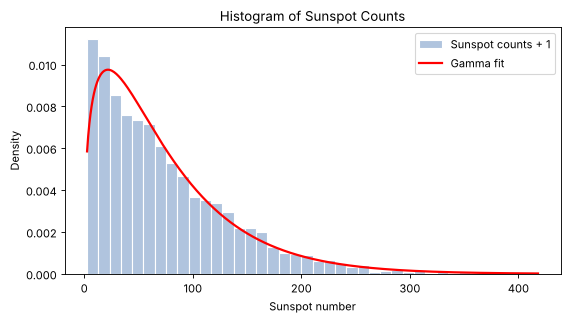

In [4]:
shifted = counts + 1
g_a, g_loc, g_b = stats.gamma.fit(shifted, floc=0)
xs = np.linspace(shifted.min(), shifted.max(), 400)
plt.figure(figsize=(8, 4))
plt.hist(shifted, bins=40, density=True, color="lightsteelblue", edgecolor="white", label="Sunspot counts + 1")
plt.plot(xs, stats.gamma.pdf(xs, g_a, scale=g_b), color="red", linewidth=2, label="Gamma fit")
plt.title("Histogram of Sunspot Counts")
plt.xlabel("Sunspot number")
plt.ylabel("Density")
plt.legend()
plt.show()
print("Maximum likelihood estimate: a =", round(g_a, 3), " b =", round(g_b, 3))
print("Skewness of the counts     :", round(stats.skew(counts), 3))

**Result:** Most months have low counts and the histogram has a long tail to the right (skewness 1.460). A gamma distribution with a = 1.410 and b = 53.253 matches this shape. These values are used later to check the sampler.

### Step 4: Metropolis sampling for three groups

The sampler starts at a = 4 and b = 10 for each group: the first 50 samples, all samples and the last 50 samples of the data. A proposal is accepted with probability min(1, posterior ratio) and flat priors are used for a and b.

In [5]:
def log_post(a, b, y):
    if a <= 0 or b <= 0:
        return -np.inf
    return stats.gamma.logpdf(y, a, scale=b).sum()

def metropolis(y, a0=4.0, b0=10.0, steps=6000, seed=1):
    rng = np.random.default_rng(seed)
    step = 2.0 / np.sqrt(len(y))
    chain = np.zeros((steps, 2))
    a, b = a0, b0
    current = log_post(a, b, y)
    accepted = 0
    for i in range(steps):
        a_new = a + rng.normal(0, step * 2)
        b_new = b * np.exp(rng.normal(0, step))
        proposal = log_post(a_new, b_new, y)
        if np.log(rng.uniform()) < proposal - current:
            a, b, current = a_new, b_new, proposal
            accepted += 1
        chain[i] = (a, b)
    return chain, accepted / steps

groups = {"First 50 samples": shifted[:50], "All samples": shifted, "Last 50 samples": shifted[-50:]}
chains = {}
rows = []
burn = 1500
for name, data in groups.items():
    chain, rate = metropolis(data)
    chains[name] = chain
    kept = chain[burn:]
    rows.append([name, len(data), round(rate, 3), round(kept[:, 0].mean(), 3), round(kept[:, 1].mean(), 3)])
group_table = pd.DataFrame(rows, columns=["Group", "n", "Acceptance rate", "Mean a", "Mean b"])
print(group_table.to_string(index=False))

           Group    n  Acceptance rate  Mean a  Mean b
First 50 samples   50            0.215   1.663  56.408
     All samples 3239            0.210   1.410  53.301
 Last 50 samples   50            0.231   4.068  34.217


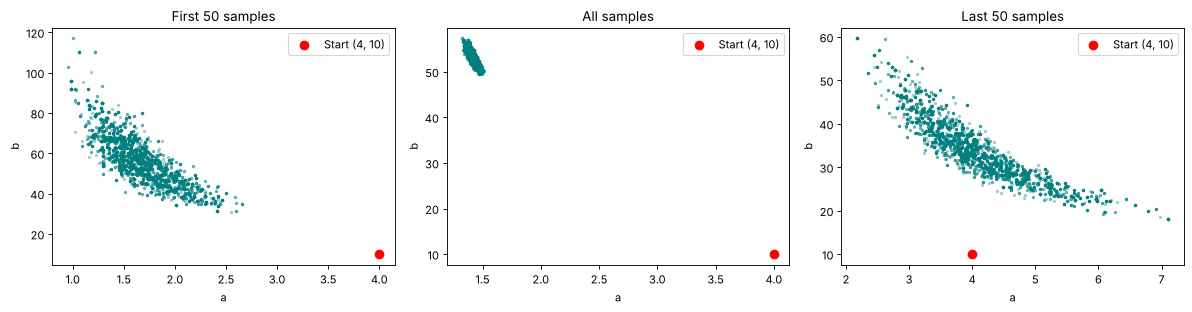

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=False)
for ax, (name, chain) in zip(axes, chains.items()):
    kept = chain[burn:]
    ax.scatter(kept[:, 0], kept[:, 1], s=4, alpha=0.3, color="teal")
    ax.scatter(4, 10, color="red", s=60, label="Start (4, 10)")
    ax.set_title(name)
    ax.set_xlabel("a")
    ax.set_ylabel("b")
    ax.legend()
plt.tight_layout()
plt.show()
width_50 = chains["First 50 samples"][burn:, 0].std()
width_all = chains["All samples"][burn:, 0].std()

**Result:** The sampler moves away from the start (4, 10) towards the region where the data is likely. The groups of 50 samples give a wide cloud of points (standard deviation of a = 0.296), while all samples give a tight cloud (standard deviation of a = 0.031). More data therefore gives a more certain estimate of a and b.

### Step 5: Traces of a and b and their histograms

The first 1500 steps are dropped as burn-in because the chain is still moving away from its starting point.

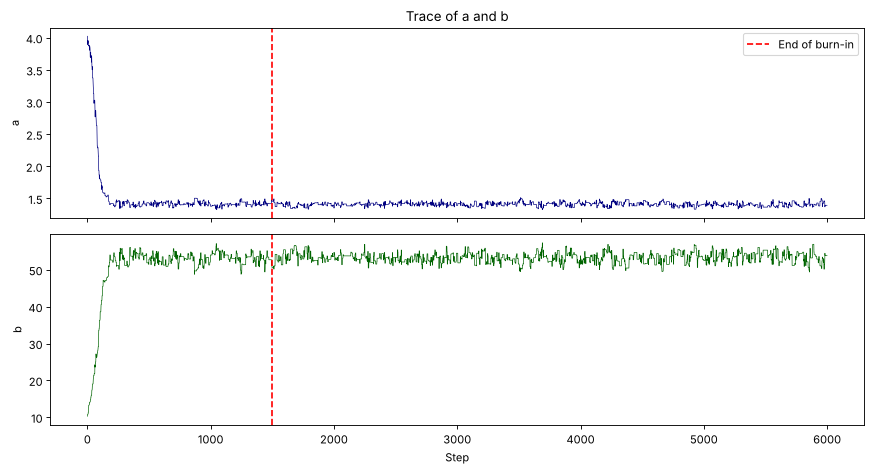

In [7]:
chain = chains["All samples"]
a_trace, b_trace = chain[:, 0], chain[:, 1]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(a_trace, color="navy", linewidth=0.6)
axes[0].axvline(burn, color="red", linestyle="--", label="End of burn-in")
axes[0].set_ylabel("a")
axes[0].set_title("Trace of a and b")
axes[0].legend()
axes[1].plot(b_trace, color="darkgreen", linewidth=0.6)
axes[1].axvline(burn, color="red", linestyle="--")
axes[1].set_ylabel("b")
axes[1].set_xlabel("Step")
plt.tight_layout()
plt.show()

Steps kept: 4500
a: mean 1.41  std 0.031
b: mean 53.301  std 1.381


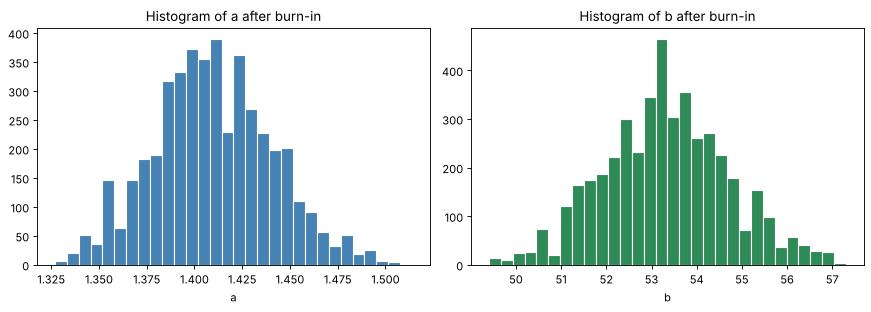

In [8]:
a_kept, b_kept = a_trace[burn:], b_trace[burn:]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(a_kept, bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Histogram of a after burn-in")
axes[0].set_xlabel("a")
axes[1].hist(b_kept, bins=30, color="seagreen", edgecolor="white")
axes[1].set_title("Histogram of b after burn-in")
axes[1].set_xlabel("b")
plt.tight_layout()
plt.show()
print("Steps kept:", len(a_kept))
print("a: mean", round(a_kept.mean(), 3), " std", round(a_kept.std(), 3))
print("b: mean", round(b_kept.mean(), 3), " std", round(b_kept.std(), 3))

**Result:** After the burn-in both traces move steadily around one level and the histograms are single bell shaped peaks. 4500 steps were kept. The posterior mean of a is 1.410 and of b is 53.301, which is close to the maximum likelihood values a = 1.410 and b = 53.253 found in Step 3.

### Step 6: Prediction of a and b

Predicted a: 1.41  95% interval: 1.351 to 1.474
Predicted b: 53.301  95% interval: 50.534 to 56.237
Expected monthly count: 74.13
95% range of a new month: 3.9 to 230.48


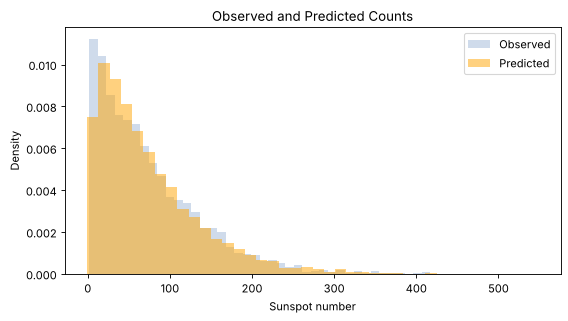

In [9]:
a_hat, b_hat = a_kept.mean(), b_kept.mean()
a_low, a_high = np.percentile(a_kept, [2.5, 97.5])
b_low, b_high = np.percentile(b_kept, [2.5, 97.5])
print("Predicted a:", round(a_hat, 3), " 95% interval:", round(a_low, 3), "to", round(a_high, 3))
print("Predicted b:", round(b_hat, 3), " 95% interval:", round(b_low, 3), "to", round(b_high, 3))

rng = np.random.default_rng(5)
pick = rng.integers(0, len(a_kept), 5000)
future = rng.gamma(a_kept[pick], b_kept[pick]) - 1
expected = a_hat * b_hat - 1
low_pred, high_pred = np.percentile(future, [2.5, 97.5])
print("Expected monthly count:", round(expected, 2))
print("95% range of a new month:", round(low_pred, 2), "to", round(high_pred, 2))

plt.figure(figsize=(8, 4))
plt.hist(counts, bins=40, density=True, alpha=0.6, color="lightsteelblue", label="Observed")
plt.hist(future, bins=40, density=True, alpha=0.5, color="orange", label="Predicted")
plt.title("Observed and Predicted Counts")
plt.xlabel("Sunspot number")
plt.ylabel("Density")
plt.legend()
plt.show()

**Result:** The predicted values are a = 1.410 (95% interval 1.351 to 1.474) and b = 53.301 (95% interval 50.534 to 56.237). The model expects a monthly sunspot number of about 74.13 while the observed mean is 74.08. A new month is predicted to fall between 3.90 and 230.48 with 95% probability, and the predicted histogram has the same right skewed shape as the observed one.